In [1]:
import pandas as pd
import numpy as np

# Load the datasets
athletes = pd.read_csv("athlete_events.csv")
noc_regions = pd.read_csv("noc_regions.csv")

In [2]:
print("Athlete data shape:", athletes.shape)
print("NOC data shape:", noc_regions.shape)

display(athletes.head())
display(noc_regions.head())

Athlete data shape: (271116, 15)
NOC data shape: (230, 3)


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


,NOC,region,notes
0,AFG,Afghanistan,NaN
1,AHO,Curacao,Netherlands Antilles
2,ALB,Albania,NaN
3,ALG,Algeria,NaN
4,AND,Andorra,NaN


In [3]:
print("DATAFRAME INFORMATION")
athletes.info()

print("\nMISSING VALUES")
print(athletes.isnull().sum())

print("\nEXACT DUPLICATE ROWS")
print(athletes.duplicated().sum())

print("\nYEAR RANGE")
print(athletes["Year"].min(), "to", athletes["Year"].max())

DATAFRAME INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  str    
 2   Sex     271116 non-null  str    
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  str    
 7   NOC     271116 non-null  str    
 8   Games   271116 non-null  str    
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  str    
 11  City    271116 non-null  str    
 12  Sport   271116 non-null  str    
 13  Event   271116 non-null  str    
 14  Medal   39783 non-null   str    
dtypes: float64(3), int64(2), str(10)
memory usage: 56.6 MB

MISSING VALUES
ID             0
Name           0
Sex            0
Age         9474
Height     60171
Weight     62875
Team           0
NOC            0
Games          0
Yea

In [4]:
olympics_clean = athletes.copy()

In [5]:
rows_before = len(olympics_clean)

olympics_clean = olympics_clean.drop_duplicates().copy()

rows_after = len(olympics_clean)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Duplicates removed:", rows_before - rows_after)

Rows before: 271116
Rows after: 269731
Duplicates removed: 1385


In [6]:
olympics_clean = olympics_clean.merge(
    noc_regions,
    on="NOC",
    how="left"
)

olympics_clean.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,region,notes
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,China,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,China,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,Denmark,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,Denmark,NaN
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,Netherlands,NaN


In [7]:
unmatched_noc = olympics_clean.loc[
    olympics_clean["region"].isnull(),
    "NOC"
].value_counts()

print(unmatched_noc)

NOC
SGP    349
ROT     12
TUV      7
UNK      2
Name: count, dtype: int64


In [8]:
manual_region_map = {
    "SGP": "Singapore",
    "ROT": "Refugee Olympic Team",
    "TUV": "Tuvalu",
    "UNK": "Unknown"
}

olympics_clean["region"] = (
    olympics_clean["region"].fillna(
        olympics_clean["NOC"].map(manual_region_map)
    )
)

In [9]:
unmatched_after_correction = olympics_clean.loc[
    olympics_clean["region"].isnull(),
    "NOC"
].value_counts()

print(unmatched_after_correction)

Series([], Name: count, dtype: int64)


In [10]:
olympics_clean.loc[
    olympics_clean["NOC"].isin(["SGP", "ROT", "TUV", "UNK"]),
    ["NOC", "Team", "region"]
].drop_duplicates()

,NOC,Team,region
578,SGP,Singapore,Singapore
6259,ROT,Refugee Olympic Athletes,Refugee Olympic Team
44161,SGP,June Climene,Singapore
60733,UNK,Unknown,Unknown
64317,TUV,Tuvalu,Tuvalu
80536,SGP,Rika II,Singapore
107955,SGP,Singapore-2,Singapore
234682,SGP,Singapore-1,Singapore


In [11]:
print(
    olympics_clean.loc[
        olympics_clean["region"].isnull(),
        "NOC"
    ].value_counts()
)

Series([], Name: count, dtype: int64)


In [12]:
# 1 if the athlete received a medal, otherwise 0
olympics_clean["Won_Medal"] = (
    olympics_clean["Medal"].notna().astype(int)
)

# Power BI-friendly medal category
olympics_clean["Medal_Status"] = (
    olympics_clean["Medal"].fillna("No Medal")
)

# Simplified gender descriptions
olympics_clean["Gender"] = (
    olympics_clean["Sex"]
    .map({"M": "Male", "F": "Female"})
    .fillna("Unknown")
)

In [13]:
print(olympics_clean["Medal_Status"].value_counts())
print(olympics_clean["Gender"].value_counts())

Medal_Status
No Medal    229959
Gold         13369
Bronze       13295
Silver       13108
Name: count, dtype: int64
Gender
Male      195353
Female     74378
Name: count, dtype: int64


In [14]:
asean_countries = [
    "Brunei",
    "Cambodia",
    "Indonesia",
    "Laos",
    "Malaysia",
    "Myanmar",
    "Philippines",
    "Singapore",
    "Thailand",
    "Vietnam"
]

asean_olympics = olympics_clean[
    olympics_clean["region"].isin(asean_countries)
].copy()

In [15]:
print("ASEAN dataset shape:", asean_olympics.shape)
print("\nRecords by country:")
print(asean_olympics["region"].value_counts())

ASEAN dataset shape: (3233, 20)

Records by country:
region
Thailand       747
Philippines    694
Malaysia       577
Indonesia      412
Singapore      349
Vietnam        216
Myanmar        111
Cambodia        63
Laos            54
Brunei          10
Name: count, dtype: int64


In [16]:
print(asean_olympics["Won_Medal"].value_counts())

Won_Medal
0    3123
1     110
Name: count, dtype: int64


In [17]:
for column in ["Age", "Height", "Weight"]:
    asean_olympics[f"{column}_Missing"] = (
        asean_olympics[column].isnull().astype(int)
    )

In [18]:
age_analysis = asean_olympics.dropna(subset=["Age"])

In [19]:
display(
    asean_olympics[
        [
            "Name",
            "Age", "Age_Missing",
            "Height", "Height_Missing",
            "Weight", "Weight_Missing"
        ]
    ].head(10)
)

,Name,Age,Age_Missing,Height,Height_Missing,Weight,Weight_Missing
251,Zulkifli Abbas,28.0,0,170.0,0,62.0,0
493,Maizurah Abdul Rahim,17.0,0,147.0,0,50.0,0
496,Chairil Anwar Abdul Aziz,24.0,0,163.0,0,61.0,0
497,Chairil Anwar Abdul Aziz,28.0,0,163.0,0,61.0,0
501,Mohamed Abdul Hadj,25.0,0,NaN,1,NaN,1
502,Jefri Kiko Bolkiah Abdul Hakeem,23.0,0,172.0,0,90.0,0
503,Jefri Kiko Bolkiah Abdul Hakeem,27.0,0,172.0,0,90.0,0
523,Zambrose Abdul Rahman,24.0,0,173.0,0,64.0,0
541,Patmawati Abdul Wahid,32.0,0,158.0,0,58.0,0
551,Roosevelt M. Abdulgafur,24.0,0,181.0,0,73.0,0


In [20]:
missing_columns = [
    "Age_Missing",
    "Height_Missing",
    "Weight_Missing"
]

has_missing = (
    asean_olympics[missing_columns].sum(axis=1) > 0
)

display(
    asean_olympics.loc[
        has_missing,
        [
            "Name", "region", "Sport",
            "Age", "Age_Missing",
            "Height", "Height_Missing",
            "Weight", "Weight_Missing"
        ]
    ].head(15)
)

,Name,region,Sport,Age,Age_Missing,Height,Height_Missing,Weight,Weight_Missing
501,Mohamed Abdul Hadj,Malaysia,Hockey,25.0,0,NaN,1,NaN,1
578,Zarinah Abdullah,Singapore,Badminton,21.0,0,NaN,1,NaN,1
579,Zarinah Abdullah,Singapore,Badminton,25.0,0,NaN,1,NaN,1
1061,Lailin Abu Hassan,Malaysia,Hockey,22.0,0,NaN,1,NaN,1
1062,Lailin Abu Hassan,Malaysia,Hockey,26.0,0,NaN,1,NaN,1
1632,Alberto Adela,Philippines,Boxing,NaN,1,NaN,1,NaN,1
1715,Jikirum Adjaluddin,Philippines,Swimming,21.0,0,NaN,1,NaN,1
1716,Jikirum Adjaluddin,Philippines,Swimming,25.0,0,NaN,1,NaN,1
1717,Jikirum Adjaluddin,Philippines,Swimming,25.0,0,NaN,1,NaN,1
1718,Jikirum Adjaluddin,Philippines,Swimming,25.0,0,NaN,1,NaN,1


In [21]:
missing_summary = pd.DataFrame({
    "Missing_Count": asean_olympics[
        ["Age", "Height", "Weight"]
    ].isnull().sum(),

    "Missing_Percentage": (
        asean_olympics[
            ["Age", "Height", "Weight"]
        ].isnull().mean() * 100
    ).round(1)
})

display(missing_summary)

,Missing_Count,Missing_Percentage
Age,171,5.3
Height,564,17.4
Weight,566,17.5


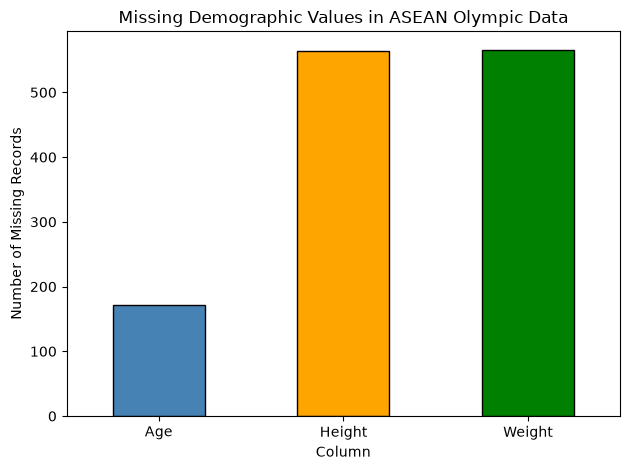

In [22]:
import matplotlib.pyplot as plt

missing_summary["Missing_Count"].plot(
    kind="bar",
    color=["steelblue", "orange", "green"],
    edgecolor="black"
)

plt.title("Missing Demographic Values in ASEAN Olympic Data")
plt.xlabel("Column")
plt.ylabel("Number of Missing Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
print("Original ASEAN rows:", len(asean_olympics))
print("Age analysis rows:", len(age_analysis))
print("Rows excluded:", len(asean_olympics) - len(age_analysis))

display(age_analysis[["Name", "Age", "region", "Sport"]].head())

Original ASEAN rows: 3233
Age analysis rows: 3062
Rows excluded: 171


,Name,Age,region,Sport
251,Zulkifli Abbas,28.0,Malaysia,Hockey
493,Maizurah Abdul Rahim,17.0,Brunei,Athletics
496,Chairil Anwar Abdul Aziz,24.0,Malaysia,Hockey
497,Chairil Anwar Abdul Aziz,28.0,Malaysia,Hockey
501,Mohamed Abdul Hadj,25.0,Malaysia,Hockey


In [24]:
asean_official_medals = (
    asean_olympics[
        asean_olympics["Medal"].notna()
    ]
    .drop_duplicates(
        subset=["Games", "NOC", "Event", "Medal"]
    )
    .copy()
)

In [25]:
print(
    asean_official_medals[
        ["region", "Medal"]
    ].value_counts()
)

print(
    "\nTotal official-style medals:",
    len(asean_official_medals)
)

region       Medal 
Thailand     Bronze    13
Indonesia    Silver    12
             Bronze    11
Thailand     Gold       9
             Silver     8
Indonesia    Gold       7
Malaysia     Silver     7
Philippines  Bronze     7
Malaysia     Bronze     4
Philippines  Silver     3
Vietnam      Silver     3
Singapore    Silver     2
             Bronze     2
Vietnam      Gold       1
Singapore    Gold       1
Name: count, dtype: int64

Total official-style medals: 90


In [26]:
print("CLEAN ASEAN DATASET")
print("Rows:", asean_olympics.shape[0])
print("Columns:", asean_olympics.shape[1])
print("Duplicate rows:", asean_olympics.duplicated().sum())

print("\nCOUNTRIES")
print(sorted(asean_olympics["region"].unique()))

print("\nYEAR RANGE")
print(
    asean_olympics["Year"].min(),
    "to",
    asean_olympics["Year"].max()
)

print("\nSEASONS")
print(asean_olympics["Season"].value_counts())

print("\nMISSING VALUES")
print(asean_olympics.isnull().sum())

CLEAN ASEAN DATASET
Rows: 3233
Columns: 23
Duplicate rows: 0

COUNTRIES
['Brunei', 'Cambodia', 'Indonesia', 'Laos', 'Malaysia', 'Myanmar', 'Philippines', 'Singapore', 'Thailand', 'Vietnam']

YEAR RANGE
1924 to 2016

SEASONS
Season
Summer    3219
Winter      14
Name: count, dtype: int64

MISSING VALUES
ID                   0
Name                 0
Sex                  0
Age                171
Height             564
Weight             566
Team                 0
NOC                  0
Games                0
Year                 0
Season               0
City                 0
Sport                0
Event                0
Medal             3123
region               0
notes             3231
Won_Medal            0
Medal_Status         0
Gender               0
Age_Missing          0
Height_Missing       0
Weight_Missing       0
dtype: int64


In [27]:
asean_olympics.to_csv(
    "asean_olympics_clean.csv",
    index=False
)

asean_official_medals.to_csv(
    "asean_official_medals.csv",
    index=False
)

print("Clean datasets exported successfully.")

Clean datasets exported successfully.


In [30]:
cleaning_log = """
# ASEAN Olympics Cleaning Log

## Duplicate Records

- Original rows: 271,116
- Duplicates removed: 1,385
- Cleaned rows: 269,731

## Missing Values

Missing Age, Height and Weight values were retained and flagged.
They were not imputed because doing so could create artificial
athlete measurements.

## Cleaning Actions

| Issue | Treatment | Reason |
|---|---|---|
| 1,385 exact duplicate rows | Removed using `drop_duplicates()` | Prevents participation and medal results from being counted more than once |
| Country names stored separately | Merged `athlete_events` with `noc_regions` using `NOC` | Adds readable country names for analysis and visualisation |
| Unmatched NOC codes | Manually mapped `SGP`, `ROT`, `TUV` and `UNK` | Ensures all NOC codes have a corresponding region |
| Non-ASEAN records | Filtered using the ten-country ASEAN list | Aligns the dataset with the project scope |
| Missing Medal values | Created `Medal_Status` and labelled them as No Medal | A blank Medal normally means that the athlete did not win a medal |
| Medal measurement | Created `Won_Medal` as a binary field | Supports medal rates and comparisons |
| Team-event medal duplication | Created a separate medal table deduplicated by Games, NOC, Event and Medal | Prevents every team member from being counted as a separate country medal |
| Missing Age, Height and Weight | Retained and flagged rather than imputed | Avoids creating artificial athlete measurements |
| Gender codes | Added readable Male and Female labels | Improves dashboard usability |
| Original columns | Retained where possible | Preserves traceability to the source data |
"""

with open(
    "ASEAN_Olympics_Cleaning_Log.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(cleaning_log)

print("Cleaning log created successfully.")

Cleaning log created successfully.


## Cleaning Actions

| Issue | Treatment | Reason |
|---|---|---|
| 1,385 exact duplicate rows | Removed using `drop_duplicates()` | Prevents participation and medal results from being counted more than once |
| Country names stored separately | Merged `athlete_events` with `noc_regions` using `NOC` | Adds readable country names for analysis and visualisation |
| Unmatched NOC codes | Manually mapped `SGP`, `ROT`, `TUV` and `UNK` | Ensures all NOC codes have a corresponding region |
| Non-ASEAN records | Filtered using the ten-country ASEAN list | Aligns the dataset with the project scope |
| Missing Medal values | Created `Medal_Status` and labelled them as No Medal | A blank Medal normally means that the athlete did not win a medal |
| Medal measurement | Created `Won_Medal` as a binary field | Supports medal rates and comparisons |
| Team-event medal duplication | Created a separate medal table deduplicated by Games, NOC, Event and Medal | Prevents every team member from being counted as a separate country medal |
| Missing Age, Height and Weight | Retained and flagged rather than imputed | Avoids creating artificial athlete measurements |
| Gender codes | Added readable Male and Female labels | Improves dashboard usability |
| Original columns | Retained where possible | Preserves traceability to the source data |